In [ ]:
!wget -O "dataset.zip" "https://data.mendeley.com/public-files/datasets/zfwkkdj6dk/files/077388af-3fc5-47fe-9017-8ff3705642f5/file_downloaded"

--2026-10-05 14:28:30--  https://data.mendeley.com/public-files/datasets/zfwkkdj6dk/files/077388af-3fc5-47fe-9017-8ff3705642f5/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.130.86, 162.159.133.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.130.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37cdb5ac-f05c-4cda-84fd-b0fd71b3fdc3 [following]
--2026-10-05 14:28:31--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37cdb5ac-f05c-4cda-84fd-b0fd71b3fdc3
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.75.98, 3.5.70.39, 3.5.71.95, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.75.98|:443... connecte

In [ ]:
!unzip dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (46).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (460).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (461).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (462).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (463).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (464).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (465).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (466).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/Neck_Blast/aug nb (467).jpg  
  inflating: Rice leaf disease classification/Rice leaf augumention/

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf

In [ ]:
!pip install split-folders

In [ ]:
import os
import shutil
import splitfolders

if os.path.exists('Dataset'):
    shutil.rmtree('Dataset')

input_folder = '/content/Rice leaf disease classification/Rice leaf augumention'

if not os.path.exists(input_folder):
    input_folder = '/content/Rice leaf disease classification'

splitfolders.ratio(input_folder, output="Dataset", seed=1337, ratio=(.8, .1, .1))
print("ডেটা সফলভাবে স্প্লিট হয়েছে এবং এক্সট্রা ফোল্ডার ক্লিন রাখা হয়েছে!")


Copying files: 13260 files [00:35, 376.72 files/s] 

ডেটা সফলভাবে স্প্লিট হয়েছে এবং এক্সট্রা ফোল্ডার ক্লিন রাখা হয়েছে!


In [ ]:
!file dataset.zip

dataset.zip: Zip archive data, at least v2.0 to extract, compression method=store


In [ ]:
train_dir = "/content/Dataset/train"
validation_dir = "/content/Dataset/val"
test_dir = "/content/Dataset/test"

BATCH_SIZE = 16
IMG_SIZE = (384, 384)

# ১. ট্রেন ডেটাসেট লোড
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    interpolation='bicubic'
)

# ২. ভ্যালিডেশন ডেটাসেট লোড
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    interpolation='bicubic'
)

# ৩. টেস্ট ডেটাসেট লোড
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    interpolation='bicubic'
)


Found 10605 files belonging to 10 classes.
Found 1321 files belonging to 10 classes.
Found 1334 files belonging to 10 classes.


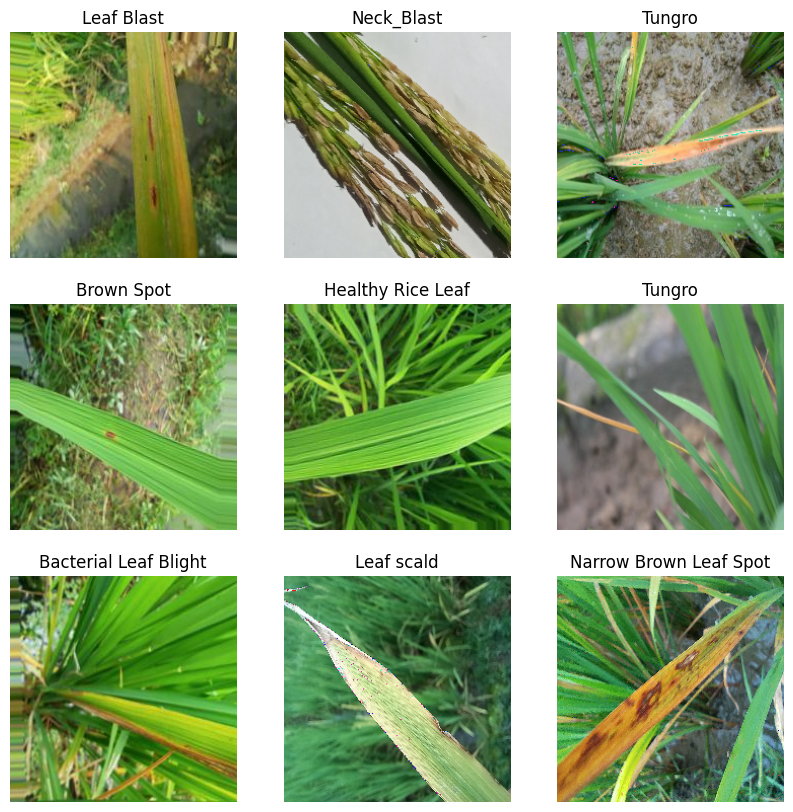

In [ ]:
class_names = train_dataset.class_names

plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
class_names

['Bacterial Leaf Blight',
 'Brown Spot',
 'Healthy Rice Leaf',
 'Leaf Blast',
 'Leaf scald',
 'Narrow Brown Leaf Spot',
 'Neck_Blast',
 'Rice Hispa',
 'Sheath Blight',
 'Tungro']

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications.efficientnet import preprocess_input

# ১. আপডেটেড ও শক্তিশালী ডাটা অগমেন্টেশন
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomTranslation(height_factor=0.2, width_factor=0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.1)
])

base_model = tf.keras.applications.EfficientNetB4(
    input_shape=(384, 384, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(384, 384, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(10, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

print("Model ready for 10 classes")


71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
২২৪ ইনপুট সাইজ এবং ১০ ক্লাসের জন্য দুর্বলতা মুক্ত আপগ্রেডেড মডেল রেডি!


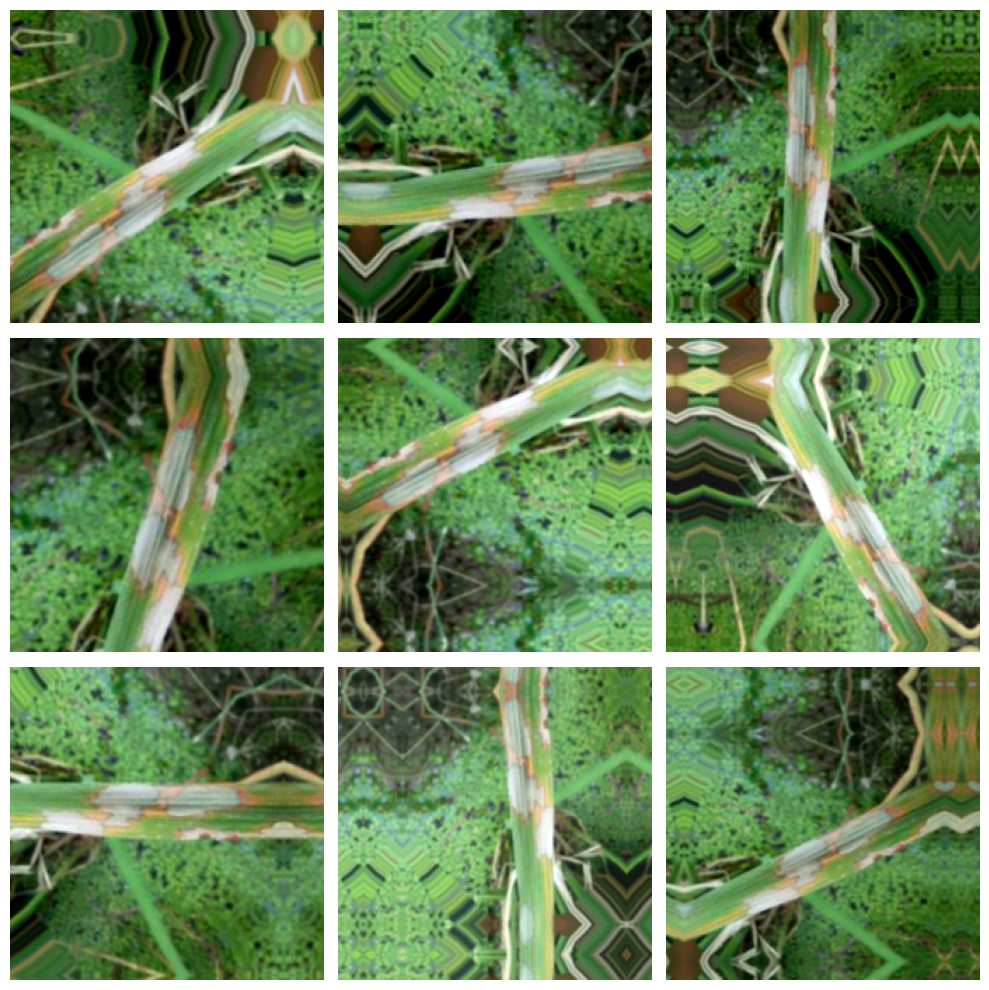

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

for images, _ in train_dataset.take(1):
    plt.figure(figsize=(10, 10))
    first_image = images[0]

    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        augmented_image = data_augmentation(tf.expand_dims(first_image, 0))

        display_image = tf.cast(augmented_image[0], tf.uint8).numpy()

        plt.imshow(display_image)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
preprocess_input = tf.keras.applications.efficientnet.preprocess_input

In [ ]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.EfficientNetB4(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet'

)

In [ ]:
image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 7, 7, 1792)


In [ ]:
base_model.trainable = False

In [ ]:
base_model.summary()

Model: "efficientnetb4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 224, 224,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,296 │ stem_conv_pad[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        192 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        432 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        192 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 48)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 48)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 12)  │        588 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 48)  │        624 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 48)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      1,152 │ block1a_se_excit

 Total params: 17,673,823 (67.42 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 17,673,823 (67.42 MB)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

global_average_layer = tf.keras.layers.GlobalAveragePooling2D()

inputs = tf.keras.Input(shape=(384, 384, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)

# # L2 Regularization & strong Dropout(0.4)
x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)


outputs = layers.Dense(10, activation='softmax')(x)


model = tf.keras.Model(inputs, outputs)

model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb4 (Functional)     │ (None, 7, 7, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       459,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,136,425 (69.18 MB)

 Trainable params: 462,090 (1.76 MB)

 Non-trainable params: 17,674,335 (67.42 MB)

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# Adding Magic callback
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001)
early_stopper = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

print("Success!")


মডেল সফলভাবে সঠিক লস ফাংশন ও কলব্যাক সহ কম্পাইল হয়েছে!


In [ ]:
initial_epochs = 20

history = model.fit(
    train_dataset,
    epochs=initial_epochs,
    validation_data=validation_dataset,
    callbacks=[lr_reducer, early_stopper]
)


Epoch 1/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 121s 298ms/step - accuracy: 0.5865 - loss: 1.7439 - val_accuracy: 0.7290 - val_loss: 1.2271 - learning_rate: 0.0010
Epoch 2/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 89s 268ms/step - accuracy: 0.6692 - loss: 1.3820 - val_accuracy: 0.7328 - val_loss: 1.1323 - learning_rate: 0.0010
Epoch 3/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 86s 260ms/step - accuracy: 0.6932 - loss: 1.2615 - val_accuracy: 0.7509 - val_loss: 1.0474 - learning_rate: 0.0010
Epoch 4/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 153s 293ms/step - accuracy: 0.7037 - loss: 1.1679 - val_accuracy: 0.7691 - val_loss: 1.0143 - learning_rate: 0.0010
Epoch 5/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 264ms/step - accuracy: 0.7127 - loss: 1.1330 - val_accuracy: 0.7835 - val_loss: 0.9515 - learning_rate: 0.0010
Epoch 6/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 266ms/step - accuracy: 0.7161 - loss: 1.1102 - val_accuracy: 0.7721 - val_loss: 0.9537 - learning_rate: 0.0010
Epoch 7/20
332/332 ━━━━━━━━━━━━━━━━━━━━ 142s 265ms/step - accuracy: 

In [ ]:
# EfficientNetB4 বেস মডেল আনফ্রিজ করা
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# অত্যন্ত ছোট লার্নিং রেটে রি-কম্পাইল (যেন প্রি-ট্রেইন্ড নলেজ নষ্ট না হয়)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

history_fine = model.fit(
    train_dataset,
    epochs=50,
    initial_epoch=history.epoch[-1] + 1,
    validation_data=validation_dataset,
    callbacks=[lr_reducer, early_stopper]
)
print("Completed!")


Epoch 21/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 147s 345ms/step - accuracy: 0.7667 - loss: 0.8592 - val_accuracy: 0.8668 - val_loss: 0.5932 - learning_rate: 1.0000e-04
Epoch 22/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 108s 325ms/step - accuracy: 0.8478 - loss: 0.6207 - val_accuracy: 0.9061 - val_loss: 0.4607 - learning_rate: 1.0000e-04
Epoch 23/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 118s 355ms/step - accuracy: 0.8864 - loss: 0.5105 - val_accuracy: 0.9281 - val_loss: 0.3937 - learning_rate: 1.0000e-04
Epoch 24/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 141s 354ms/step - accuracy: 0.9103 - loss: 0.4398 - val_accuracy: 0.9463 - val_loss: 0.3409 - learning_rate: 1.0000e-04
Epoch 25/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 133s 326ms/step - accuracy: 0.9229 - loss: 0.3945 - val_accuracy: 0.9553 - val_loss: 0.2901 - learning_rate: 1.0000e-04
Epoch 26/50
332/332 ━━━━━━━━━━━━━━━━━━━━ 108s 325ms/step - accuracy: 0.9388 - loss: 0.3455 - val_accuracy: 0.9599 - val_loss: 0.2784 - learning_rate: 1.0000e-04
Epoch 27/50
332/332 ━━━━━━━━━━━━━━

42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 239ms/step

======================= HIGH-PRECISION EVALUATION REPORT ======================
                        precision    recall  f1-score   support

 Bacterial Leaf Blight     0.9835    0.9835    0.9835       121
            Brown Spot     0.9936    0.9936    0.9936       156
     Healthy Rice Leaf     1.0000    1.0000    1.0000       109
            Leaf Blast     0.9831    0.9886    0.9858       176
            Leaf scald     0.9852    0.9925    0.9888       134
Narrow Brown Leaf Spot     0.9894    0.9688    0.9789        96
            Neck_Blast     1.0000    1.0000    1.0000       100
            Rice Hispa     1.0000    1.0000    1.0000       131
         Sheath Blight     1.0000    1.0000    1.0000       164
                Tungro     1.0000    1.0000    1.0000       147

              accuracy                         0.9933      1334
             macro avg     0.9935    0.9927    0.9931      1334
          weighted avg     0.9933    0.9933

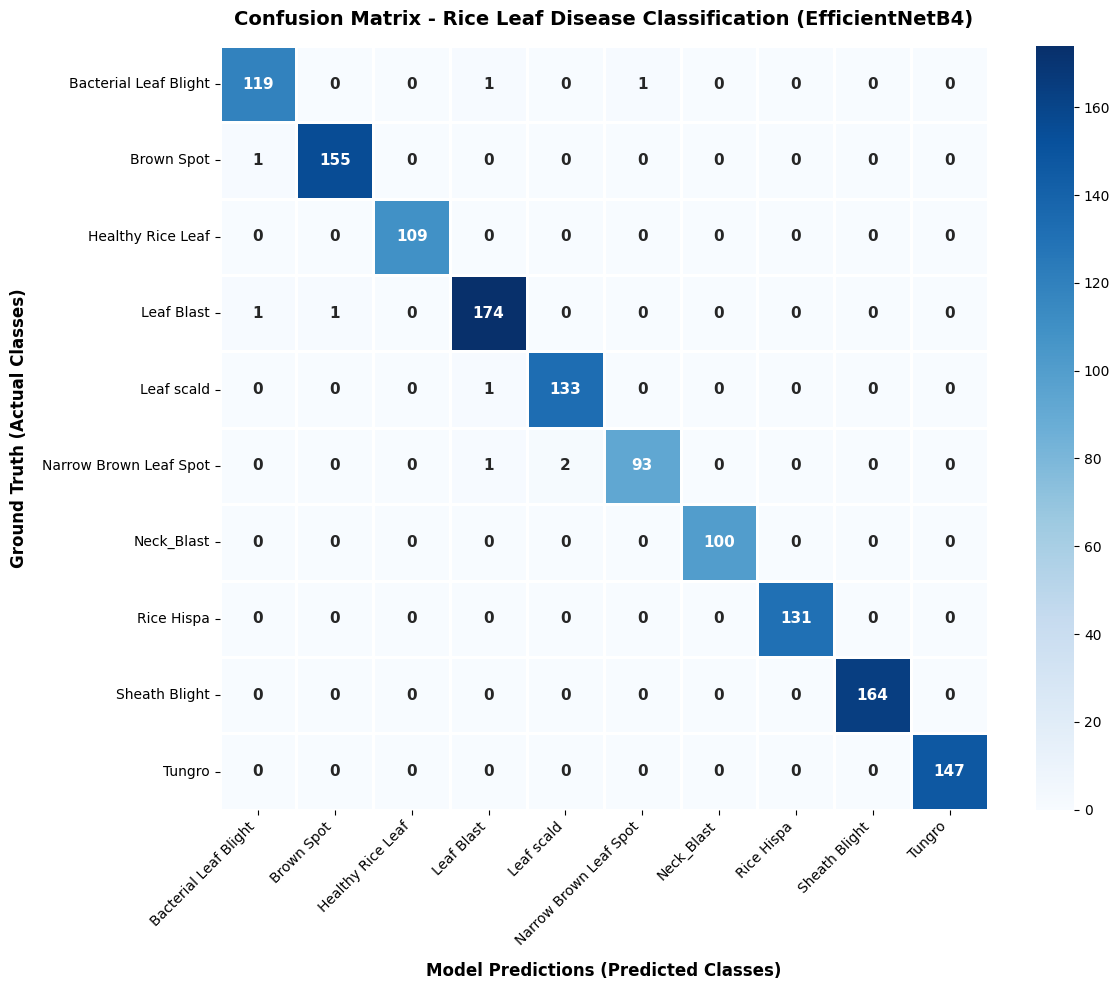

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.metrics import classification_report, confusion_matrix

test_dir = "/content/Dataset/test"
class_names = sorted(os.listdir(test_dir))


# ১. টেস্ট ডেটাসেট থেকে একবারে দ্রুত প্রেডিকশন বের করা
preds = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(preds, axis=1)

# টেস্ট ডেটাসেটের আসল লেবেল (y_true) সংগ্রহ করা
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

# ২. নিখুঁত Classification Report প্রিন্ট করা
print("\n" + "="*23 + " HIGH-PRECISION EVALUATION REPORT " + "="*22)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("="*79 + "\n")

# ৩. Confusion Matrix তৈরি করা
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1.0,
    linecolor='white',
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 11, "weight": "bold"}
)

plt.title('Confusion Matrix - Rice Leaf Disease Classification (EfficientNetB4)', fontsize=14, pad=15, weight='bold')
plt.ylabel('Ground Truth (Actual Classes)', fontsize=12, labelpad=10, weight='bold')
plt.xlabel('Model Predictions (Predicted Classes)', fontsize=12, labelpad=10, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


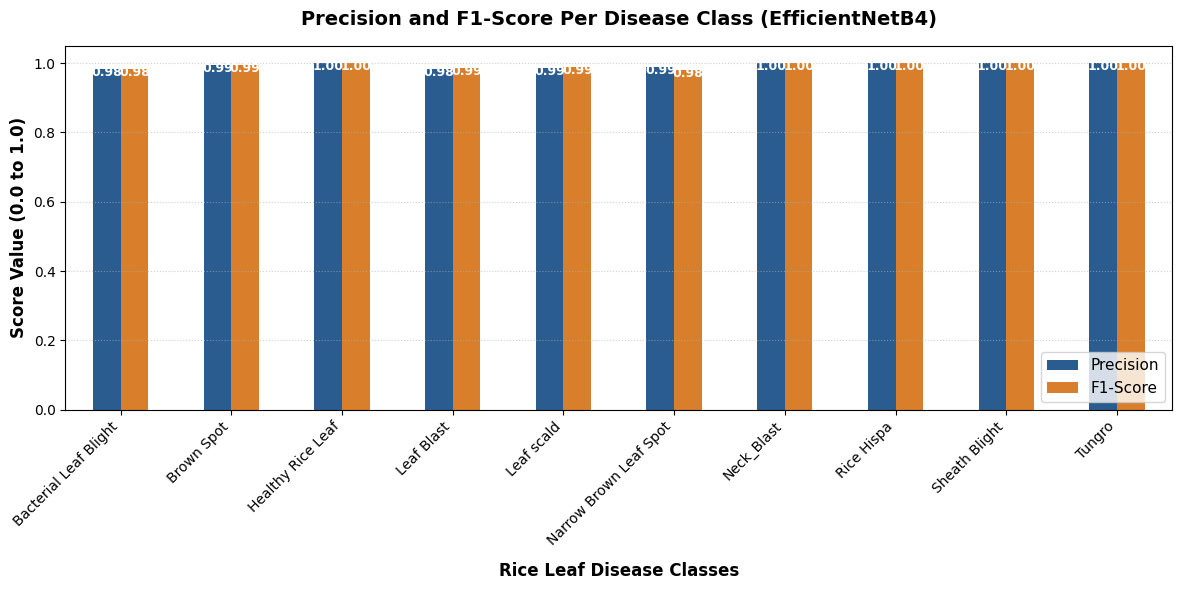

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

# ১. ক্লাসিফিকেশন রিপোর্ট ডিকশনারি আকারে তৈরি করা
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

# ২. ডিকশনারি থেকে ডেটাফ্রেমে রূপান্তর
df = pd.DataFrame(report).T
df_metrics = df.loc[class_names]

# ৩. আকর্ষণীয় বার চার্ট বা গ্রাফ প্লট করা
ax = df_metrics[['precision', 'f1-score']].plot(kind='bar', figsize=(12, 6), color=['#2b5c8f', '#d97f2b'])

plt.title('Precision and F1-Score Per Disease Class (EfficientNetB4)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Rice Leaf Disease Classes', fontsize=12, weight='bold', labelpad=10)
plt.ylabel('Score Value (0.0 to 1.0)', fontsize=12, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(['Precision', 'F1-Score'], fontsize=11, loc='lower right')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height - 0.05),
                    ha='center', va='center', xytext=(0, 10), textcoords='offset points',
                    fontsize=9, color='white', weight='bold')

plt.tight_layout()
plt.show()


In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"চুড়ান্ত টেস্ট লস (Test Loss): {test_loss:.4f}")
print(f"চুড়ান্ত টেস্ট অ্যাকুরেসি (Test Accuracy): {test_accuracy * 100:.2f}%")


42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 266ms/step - accuracy: 0.9933 - loss: 0.0656
চুড়ান্ত টেস্ট লস (Test Loss): 0.0656
চুড়ান্ত টেস্ট অ্যাকুরেসি (Test Accuracy): 99.33%


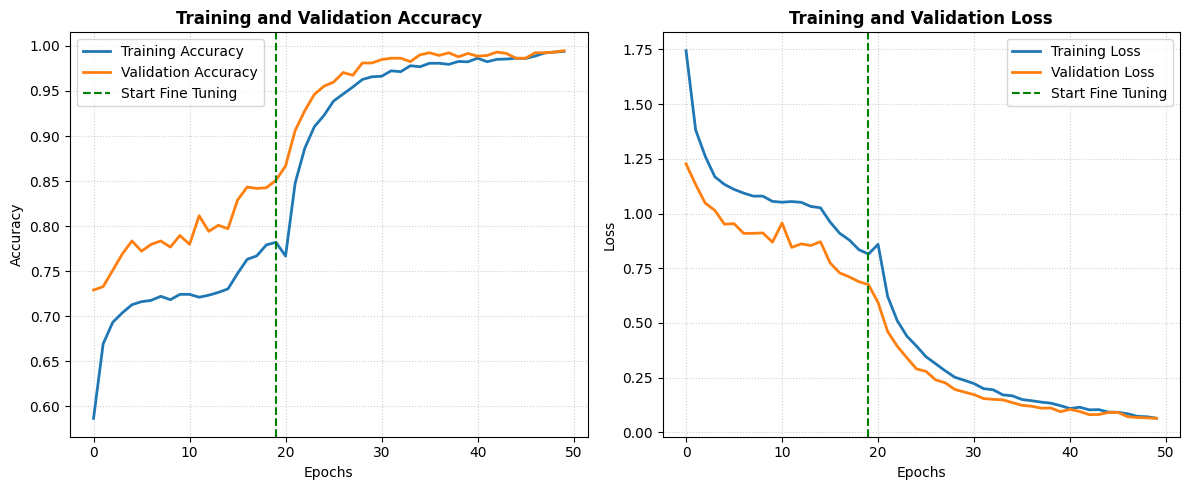

In [ ]:
import matplotlib.pyplot as plt

# ফ্রেশ ডেটা নেওয়া (উভয় ফেজের হিস্ট্রি যুক্ত করা)
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']
phase1_end_index = len(history.history['accuracy']) - 1

plt.figure(figsize=(12, 5))

# ১. নিখুঁত একুরেসি গ্রাফ
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy', color='tab:blue', linewidth=2)
plt.plot(val_acc, label='Validation Accuracy', color='tab:orange', linewidth=2)
plt.axvline(x=phase1_end_index, color='green', linestyle='--', label='Start Fine Tuning')
plt.title('Training and Validation Accuracy', fontsize=12, weight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# ২. নিখুঁত লস গ্রাফ
plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss', color='tab:blue', linewidth=2)
plt.plot(val_loss, label='Validation Loss', color='tab:orange', linewidth=2)
plt.axvline(x=phase1_end_index, color='green', linestyle='--', label='Start Fine Tuning')
plt.title('Training and Validation Loss', fontsize=12, weight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import tensorflow as tf
from google.colab import files
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input

print("Please upload a rice leaf image to test:")
uploaded = files.upload()
class_names = [
    'Bacterial Leaf Blight',  # Index 0
    'Brown Spot',             # Index 1
    'Healthy Rice Leaf',      # Index 2
    'Leaf Blast',             # Index 3
    'Leaf scald',             # Index 4
    'Narrow Brown Leaf Spot', # Index 5
    'Neck_Blast',             # Index 6
    'Rice Hispa',             # Index 7
    'Sheath Blight',          # Index 8
    'Tungro'                  # Index 9
]

for filename in uploaded.keys():
    img_path = filename
    # ১. সঠিক সাইজে ছবি লোড
    img = image.load_img(img_path, target_size=(224, 224))

    # ২. অ্যারে রূপান্তর ও ব্যাচ ডাইমেনশন (1, 224, 224, 3)
    img_array = image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    # ৩. EfficientNetB4 এর জন্য প্রি-প্রসেসিং
    img_array = preprocess_input(img_array)

    # ৪. মডেল প্রেডিকশন
    predictions = model.predict(img_array)
    probabilities = predictions[0]

    predicted_idx = np.argmax(probabilities)
    predicted_class = class_names[predicted_idx]
    confidence = 100 * probabilities[predicted_idx]

    print(f"\n================= RESULT =================")
    print(f"Predicted Disease : {predicted_class}")
    print(f"Confidence Score  : {confidence:.2f}%")
    print(f"==========================================")



Please upload a rice leaf image to test:


Saving d.png to d.png


NameError: name 'model' is not defined

In [ ]:
model_save_path = 'rice_leaf_disease_efficientnetB4_90plus.keras'

model.save(model_save_path)
print(f"Save {model_save_path} Successful!")


Save rice_leaf_disease_efficientnetB4_90plus.keras Successful!
